# Continuous heating of fluid – energy demand model

*Thermal activation of fluid products › Continuous heating of fluid* (manuscript Fig. 1)

**Examples** (Fig. 1, same model for all):
| Process | Products |
|---|---|
| Pasteurization | dairy products, beverages, fruit juice, tea and coffee concentrate |
| Continuous sterilization | cream and sauces, liquid pharmaceuticals, UHT milk |

This notebook checks the model the app runs: **`model.py`** in this folder. It holds no formulas of its own:
everything is imported from `model.py`, so what is checked here is exactly what the app calculates.

$$Q_{heating}=\dot m\,c_p\,(T_{process}-T_{in})+\frac1t\sum_i A\,U\,(T_i-T_{amb})\quad(18)$$
$$Q_{cooling}=\dot m\,c_p\,(T_{process}-T_{out})-\frac1t\sum_i A\,U\,(T_i-T_{amb})\quad(19)$$

($T_{process}$ is $T_{pasteur}$ in the manuscript.)

1. Example calculation
2. Figures and simplified P&ID (saved as `pid.svg`)
3. Validation against the manuscript
4. Comparison with the original notebook `energy_demand_models_notebook_1.ipynb` (left unchanged)

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, FancyBboxPatch, Polygon
from IPython.display import display, Markdown

try:
    import process_models
except ImportError:            # not installed: use the copy in this repository
    import sys
    sys.path.insert(0, str(Path.cwd().parents[1]))   # .../process_models (the folder holding the package)

from process_models import PROCESSES, run_process
from process_models.continuous_heating_of_fluid.model import MODEL, calculate

KEY = MODEL.key

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

print(f"{MODEL.name} v{MODEL.version} | processes found by the app: {list(PROCESSES)}")

Continuous heating of fluid v1.0 | processes found by the app: ['autoclaving', 'conductive_drying', 'continuous_bath_heating', 'continuous_heating_of_fluid', 'convective_drying', 'thermal_phase_change']


## 1  Example calculation
Only the **required** inputs are given; everything else falls back to its default.
Values of the main.py example: 3000 L/h · 1.045 kg/L, cp = 3.89 kJ/(kg K) (= default of *Juice (generic)*).

In [2]:
result, audit = run_process(KEY, mass_flow_kg_h=3000 * 1.045, T_in=4, T_process=90, T_out=4)

display(Markdown("**Inputs** (required / optional, source of each value)"))
display(pd.DataFrame(audit))
for w in result.warnings:
    print("WARNING:", w)
display(Markdown("**Results**"))
display(pd.DataFrame(result.summary()))
display(Markdown("**Stream data** (what the app hands to the pinch analysis)"))
display(pd.DataFrame(result.stream_table()))

**Inputs** (required / optional, source of each value)

,Symbol,Input,Value,Unit,Type,Source,Manuscript / note
0,m_product,Product mass flow rate,"3,135.000",kg/h,required,user input,"Sect. 'Continuous heating of fluids', input list"
1,T_in,Product inlet temperature,4.000,degC,required,user input,"Sect. 'Continuous heating of fluids', input list"
2,T_pasteur,"Process temperature (e.g. pasteurization, sterilization)",90.000,degC,required,user input,"Sect. 'Continuous heating of fluids', input list"
3,T_out,Outlet temperature after cooling,4.000,degC,required,user input,"Sect. 'Continuous heating of fluids', input list"
4,,Product (selects default cp),Juice (generic),-,optional,default,Only used to pick a default cp if cp is not given.
5,"cp,product",Specific heat capacity of product,3.890,kJ/(kg K),optional,"preset (Juice (generic)), not from manuscript","Sect. 'Continuous heating of fluids', input list | Required in the manuscript; here op..."
6,dT_margin,Safety margin above process temperature,0.000,K,optional,default,Sect. 'Continuous heating of fluids' (1st paragraph) | Manuscript: temperature 'slight...
7,A_pasteur,"Heat-losing surface (pipes, holding tube, exchangers)",0.000,m2,optional,default,"Eq. (18), (19) loss term | 0 = no heat losses (as in the validation case)."
8,U_pasteur,Overall heat transfer coefficient to ambient,1.000,W/(m2 K),optional,default,"Eq. (18), (19) loss term | Dummy value; only effective if loss_area > 0."
9,T_amb,Ambient temperature,20.000,degC,optional,default,"Eq. (18), (19) loss term"


**Results**

,Quantity,Symbol,Value,Unit,Manuscript ref.
0,"Heating demand, sensible",m*cp*(T_process - T_in),291.329,kW,"Eq. (18), 1st term"
1,Heat losses during heating,(1/t) sum A*U*(T_i - T_amb),0.000,kW,"Eq. (18), 2nd term"
2,HEATING DEMAND,Q_heating,291.329,kW,Eq. (18)
3,"Cooling demand, sensible",m*cp*(T_process - T_out),291.329,kW,"Eq. (19), 1st term"
4,Heat losses during cooling,(1/t) sum A*U*(T_i - T_amb),0.000,kW,"Eq. (19), 2nd term (subtracted)"
5,COOLING DEMAND,Q_cooling,291.329,kW,Eq. (19)
6,Sum heating + cooling (gross),Q_heating + Q_cooling,582.657,kW,= classes.py calculate_total_energy()[2]
7,Heat capacity flow rate,m*cp,3.388,kW/K,-


**Stream data** (what the app hands to the pinch analysis)

,stream,type,T_supply_degC,T_target_degC,CP_kW_per_K,Q_kW
0,product heating,cold,4.000,90.000,3.388,291.329
1,product cooling,hot,90.000,4.000,3.388,291.329


## 2  Figures and simplified P&ID

In [3]:
def plot_demand_breakdown(res):
    """Terms of Eq. (18) and (19): sensible term, loss term (signed as in the equation) and total."""
    fig, ax = plt.subplots(figsize=(8, 4.2))
    cats = ["Sensible term\nm*cp*dT", "Loss term\n(signed as in Eq.)", "Total demand"]
    heating = [res.Q_sensible_heating, res.Q_loss_heating, res.Q_heating]
    cooling = [res.Q_sensible_cooling, -res.Q_loss_cooling, res.Q_cooling]
    x, w = np.arange(len(cats)), 0.38
    b1 = ax.bar(x - w / 2, heating, w, color="#d9822b", label="Heating, Eq. (18)")
    b2 = ax.bar(x + w / 2, cooling, w, color="#4c78a8", label="Cooling, Eq. (19)")
    for bars in (b1, b2):
        for b in bars:
            h = b.get_height()
            ax.annotate(f"{h:,.1f}", (b.get_x() + b.get_width() / 2, h), ha="center",
                        va="bottom" if h >= 0 else "top", fontsize=9, xytext=(0, 2 if h >= 0 else -2),
                        textcoords="offset points")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(cats)
    ax.set(ylabel="Thermal power [kW]", title="Energy demand of continuous heating of fluid")
    ax.legend(fontsize=8)
    fig.tight_layout()
    return fig


def plot_stream_data(res):
    """Temperature vs. heat flow of the heating and cooling demand (both starting at 0 kW)."""
    v = res.inputs
    fig, ax = plt.subplots(figsize=(7, 4.2))
    ax.plot([0, res.Q_heating], [v["T_in"], res.T_process_eff], "b-o", label="Product heating (cold stream)")
    ax.plot([0, res.Q_cooling], [v["T_out"], res.T_process_eff], "r-o", label="Product cooling (hot stream)")
    ax.set(xlabel="Heat flow [kW]", ylabel="Temperature [degC]", title="Stream data of continuous heating of fluid")
    ax.legend(fontsize=8)
    fig.tight_layout()
    return fig


def sweep(values, param, grid):
    rows = []
    for x in grid:
        try:
            r = calculate({**values, param: float(x)})
            rows.append({param: x, "Q_heating": r.Q_heating, "Q_cooling": r.Q_cooling})
        except ValueError:
            continue
    return pd.DataFrame(rows)


def plot_sensitivity(res):
    """One-at-a-time sensitivity of Q_heating and Q_cooling."""
    v = res.inputs
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sweeps = [("T_process", np.linspace(v["T_process"] - 15, v["T_process"] + 15, 31), "Process temperature [degC]"),
              ("mass_flow_kg_h", np.linspace(0.5, 1.5, 31) * v["mass_flow_kg_h"], "Mass flow rate [kg/h]")]
    for ax, (param, grid, xlabel) in zip(axes, sweeps):
        df = sweep(v, param, grid)
        ax.plot(df[param], df["Q_heating"], label="Q_heating (Eq. 18)")
        ax.plot(df[param], df["Q_cooling"], label="Q_cooling (Eq. 19)")
        ax.axvline(v[param], color="grey", ls="--", lw=0.8)
        ax.set(xlabel=xlabel, ylabel="Thermal power [kW]")
        ax.legend(fontsize=8)
    fig.suptitle("Sensitivity (one parameter varied, all others fixed)")
    fig.tight_layout()
    return fig

In [4]:
def draw_pid(res):
    """Simplified P&ID of the continuous heating line (ISA-5.1 style tags). Duties come from the demand model."""
    v = res.inputs
    fig, ax = plt.subplots(figsize=(16, 6.6))
    ax.set_xlim(0, 20); ax.set_ylim(0, 7.2); ax.set_aspect("equal"); ax.axis("off")
    LW, y0 = 1.8, 3.5                # line width, y of the product line

    def line(xs, ys, ls="-", lw=LW, color="k"):
        ax.plot(xs, ys, ls=ls, lw=lw, color=color, solid_capstyle="butt", zorder=2)

    def arrow(x0, y0_, x1, y1_):
        ax.annotate("", xy=(x1, y1_), xytext=(x0, y0_), zorder=3,
                    arrowprops=dict(arrowstyle="-|>", lw=LW, color="k", mutation_scale=14))

    def zig(x0, x1, y, amp=0.16, n=8):
        xs = np.linspace(x0, x1, 2 * n + 1)
        ys = y + amp * np.array([0] + [(-1) ** i for i in range(2 * n - 1)] + [0])
        ax.plot(xs, ys, color="k", lw=1.3, zorder=4)

    def bubble(x, y, tag, num, temp=None, r=0.42, text_above=True):
        ax.add_patch(Circle((x, y), r, fc="white", ec="k", lw=1.4, zorder=5))
        ax.text(x, y + 0.1, tag, ha="center", va="center", fontsize=8.5, fontweight="bold", zorder=6)
        ax.text(x, y - 0.16, num, ha="center", va="center", fontsize=8, zorder=6)
        if temp is not None:
            ty = y + r + 0.25 if text_above else y - r - 0.25
            ax.text(x, ty, temp, ha="center", va="center", fontsize=9, color="firebrick", fontweight="bold")

    def valve(x, y, side=+1):
        for sgn in (+1, -1):
            ax.add_patch(Polygon([(x - .25, y + sgn * .22), (x + .25, y + sgn * .22), (x, y)],
                                 fc="white", ec="k", lw=1.4, zorder=5))
        ax.plot([x, x + side * 0.45], [y, y], color="k", lw=1.2, zorder=5)
        ax.add_patch(Circle((x + side * 0.65, y), 0.2, fc="white", ec="k", lw=1.2, zorder=5))

    # ---- equipment -----------------------------------------------------------------------
    ax.add_patch(FancyBboxPatch((0.4, 2.5), 1.8, 2.0, boxstyle="round,pad=0.02,rounding_size=0.3",
                                fc="#eef3f8", ec="k", lw=1.6, zorder=3))
    ax.text(1.3, y0, "T-101\nFeed tank", ha="center", va="center", fontsize=9)
    ax.add_patch(Circle((4.0, y0), 0.45, fc="white", ec="k", lw=1.6, zorder=4))
    ax.add_patch(Polygon([(3.8, y0 - .28), (3.8, y0 + .28), (4.3, y0)], fc="k", zorder=5))
    ax.text(4.0, y0 - 0.8, "P-101", ha="center", fontsize=9)
    ax.add_patch(Circle((7.5, y0), 0.6, fc="white", ec="k", lw=1.6, zorder=4)); zig(7.05, 7.95, y0, 0.15, 3)
    ax.text(7.5, y0 + 0.95, f"E-102 Heater\nQ_heating = {res.Q_heating:,.1f} kW", ha="center", fontsize=9)
    ax.add_patch(FancyBboxPatch((9.8, y0 - 0.3), 3.0, 0.6, boxstyle="round,pad=0.0,rounding_size=0.3",
                                fc="white", ec="k", lw=1.6, zorder=4))
    zig(10.2, 12.4, y0, 0.14, 6)
    ax.text(11.3, y0 + 0.7, f"HT-101 Holding tube\nT = {res.T_process_eff:.1f} degC", ha="center", fontsize=9)
    ax.add_patch(Circle((15.0, y0), 0.6, fc="white", ec="k", lw=1.6, zorder=4)); zig(14.55, 15.45, y0, 0.15, 3)
    ax.text(15.0, y0 - 1.0, f"E-103 Cooler\nQ_cooling = {res.Q_cooling:,.1f} kW", ha="center", fontsize=9)
    ax.add_patch(Rectangle((18.0, y0 - 0.6), 1.8, 1.2, fc="#eef3f8", ec="k", lw=1.6, zorder=3))
    ax.text(18.9, y0, "To filling /\nstorage", ha="center", va="center", fontsize=8.5)

    # ---- product line ---------------------------------------------------------------------
    line([2.2, 3.55], [y0, y0]); line([4.45, 6.9], [y0, y0]); line([8.1, 9.8], [y0, y0])
    line([12.8, 14.4], [y0, y0]); line([15.6, 18.0], [y0, y0])
    arrow(4.7, y0, 5.1, y0); arrow(8.6, y0, 9.0, y0); arrow(13.3, y0, 13.7, y0); arrow(16.3, y0, 16.7, y0)

    # ---- heater utility (from below) with control valve TV-101 ----------------------------
    line([8.0, 8.0], [0.5, y0 - 0.6]); line([7.0, 7.0], [0.5, y0 - 0.6])
    valve(8.0, 1.5, side=+1); ax.text(8.0, 1.95, "TV-101", ha="left", fontsize=8)
    ax.text(8.0, 0.25, "Hot utility in", ha="center", fontsize=8); ax.text(7.0, 0.25, "return", ha="center", fontsize=8)
    line([9.6, 9.6], [1.92, y0], ls=":", lw=1.1)
    bubble(9.6, 1.5, "TIC", "101", f"{res.T_process_eff:.1f} degC", text_above=False)
    line([8.85, 9.18], [1.5, 1.5], ls="--", lw=1.1)

    # ---- cooler utility (from above) with control valve TV-102 ----------------------------
    line([15.5, 15.5], [y0 + 0.6, 6.4]); line([14.5, 14.5], [y0 + 0.6, 6.4])
    valve(15.5, 5.2, side=+1); ax.text(15.5, 5.65, "TV-102", ha="left", fontsize=8)
    ax.text(15.5, 6.65, "Cold utility in", ha="center", fontsize=8); ax.text(14.5, 6.65, "return", ha="center", fontsize=8)
    line([17.1, 17.1], [4.78, y0], ls=":", lw=1.1)
    bubble(17.1, 5.2, "TIC", "102", f"{v['T_out']:.1f} degC")
    line([16.35, 16.68], [5.2, 5.2], ls="--", lw=1.1)

    # ---- inlet instruments ------------------------------------------------------------------
    line([2.9, 2.9], [y0, y0 + 0.58], ls=":", lw=1.1)
    bubble(2.9, y0 + 1.0, "TI", "101", f"{v['T_in']:.1f} degC")
    line([5.3, 5.3], [y0, y0 + 0.58], ls=":", lw=1.1)
    bubble(5.3, y0 + 1.0, "FIC", "101", f"{v['mass_flow_kg_h']:,.0f} kg/h")

    ax.text(0.3, 0.1, "Simplified P&ID (ISA-5.1 style tags), generated from the demand model - not for construction. "
            "Heat recovery is not part of this model.\n"
            f"m = {v['mass_flow_kg_h']:,.0f} kg/h, cp = {v['cp']:.2f} kJ/(kg K)", fontsize=8.5, color="dimgrey", va="bottom")
    ax.set_title("Continuous heating of fluid - simplified P&ID", fontsize=12)
    return fig

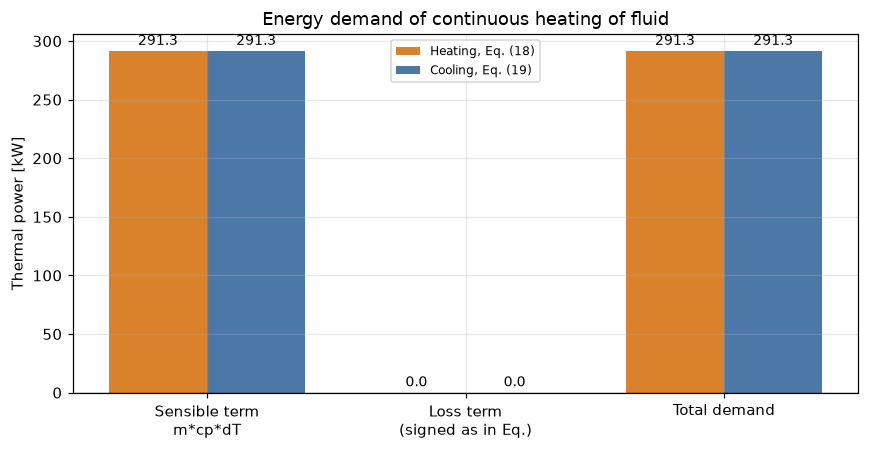

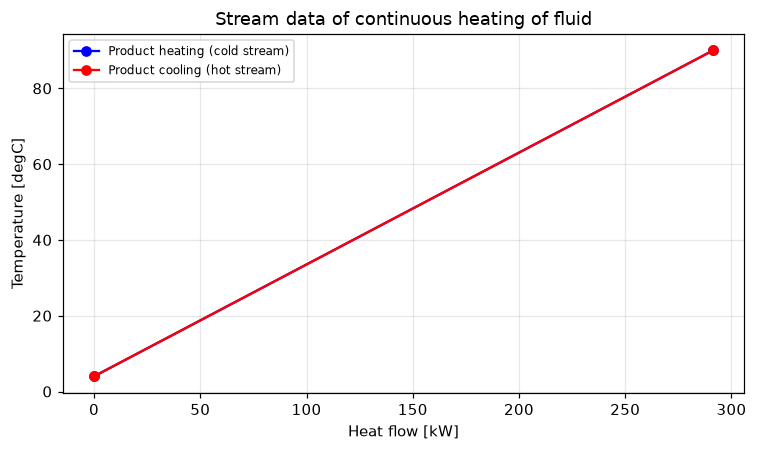

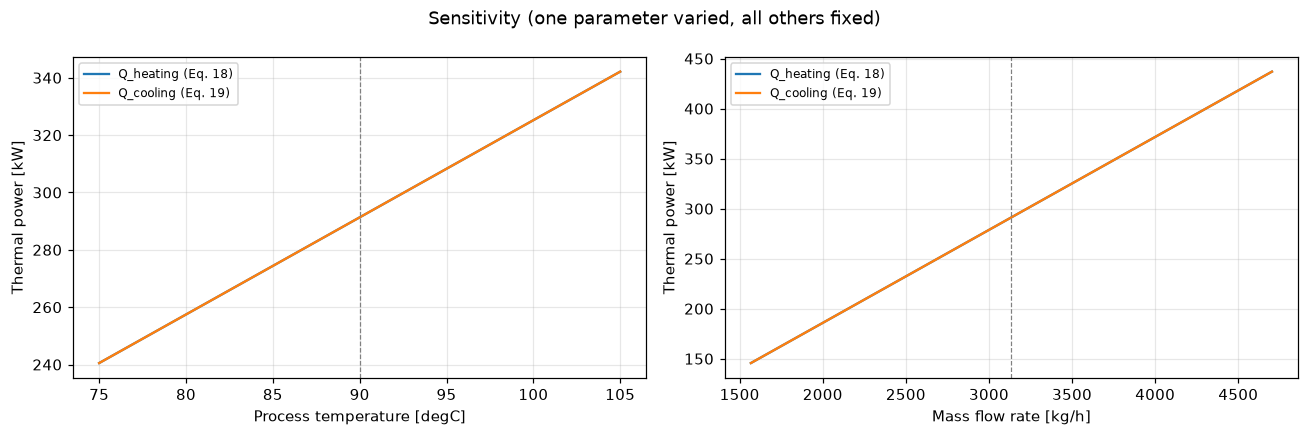

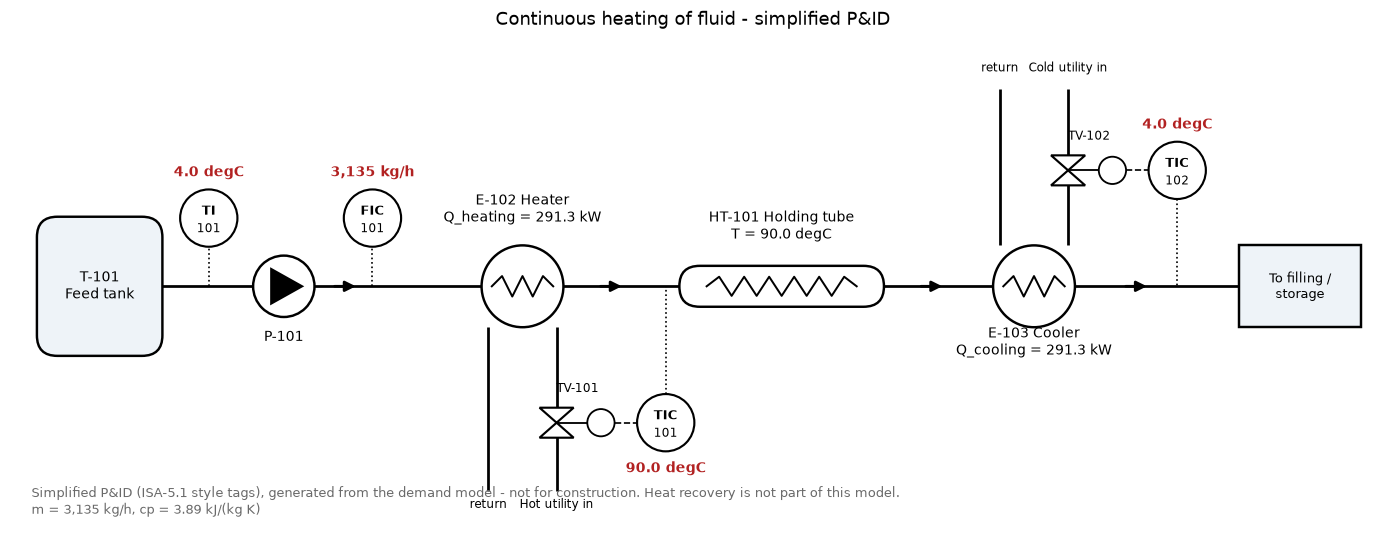

In [5]:
for fn in (plot_demand_breakdown, plot_stream_data, plot_sensitivity):
    fn(result)
    plt.show()

fig = draw_pid(result)
fig.savefig("pid.svg", bbox_inches="tight")   # P&ID of the example, kept next to model.py
plt.show()

## 3  Validation against the manuscript
Comparison with the numbers in *Validation of Process Demand Models*.

The manuscript validates this model with a pasteurization case (orange juice, reference [26]).

**Points found in the manuscript (pasteurization case):**
1. **456 kg/h does not give 291 kW.** The main.py values (3000 L/h · 1.045 kg/L = **3135 kg/h**, cp = 3890 J/(kg K),
   4 → 90 → 4 °C) give exactly 291.3 kW. The mass flow in the manuscript text is most likely wrong.
2. The validation section also states 0.13 kg/s (= 468 kg/h) *and* 8.33 kg/s (probably copied from the paper drying case).
3. $T_{out}$ is missing in the text; main.py confirms 4 °C.
4. The "relative deviation" in the manuscript refers to the model value (12.5/291.3 = 4.29 %), not to the reference value.

In [6]:
REF = dict(Q_ref=278.8, Q_model=291.3)   # printed in the manuscript (validation section)

case_A, _ = run_process(KEY, mass_flow_kg_h=456, T_in=4, T_process=90, T_out=4, cp=3.89)       # as printed
case_B, _ = run_process(KEY, mass_flow_kg_h=3000 * 1.045, T_in=4, T_process=90, T_out=4, cp=3.89)  # main.py

display(pd.DataFrame({
    "Manuscript": [REF["Q_model"], 456.0],
    "Case A (manuscript inputs)": [case_A.Q_heating, 456.0],
    "Case B (main.py inputs)": [case_B.Q_heating, 3135.0],
}, index=["Q_heating [kW]  (Eq. 18)", "Mass flow [kg/h]"]))

dev = abs(REF["Q_model"] - REF["Q_ref"])
print(f"Manuscript model vs. reference [26]: |{REF['Q_model']} - {REF['Q_ref']}| = {dev:.1f} kW")
print(f"  relative to model value    : {dev / REF['Q_model']:.2%}  (this is what the manuscript prints: 4.29 %)")
print(f"  relative to reference value: {dev / REF['Q_ref']:.2%}")

# consistency checks
r, _ = run_process(KEY, mass_flow_kg_h=1000, T_in=10, T_process=85, T_out=20, cp=3.9)
assert abs(r.Q_heating - 1000 / 3600 * 3.9 * 75) < 1e-9                        # Eq. (18) without losses
assert abs(r.Q_cooling - 1000 / 3600 * 3.9 * 65) < 1e-9                        # Eq. (19) without losses
r_loss, _ = run_process(KEY, mass_flow_kg_h=1000, T_in=10, T_process=85, T_out=20, cp=3.9,
                        loss_area=5, U_value=2)
assert r_loss.Q_heating > r.Q_heating and r_loss.Q_cooling < r.Q_cooling       # losses: + heating, - cooling
print("All consistency checks passed.")

,Manuscript,Case A (manuscript inputs),Case B (main.py inputs)
Q_heating [kW] (Eq. 18),291.300,42.375,291.329
Mass flow [kg/h],456.000,456.000,"3,135.000"


Manuscript model vs. reference [26]: |291.3 - 278.8| = 12.5 kW
  relative to model value    : 4.29%  (this is what the manuscript prints: 4.29 %)
  relative to reference value: 4.48%
All consistency checks passed.


## 4  Comparison with the original notebook
The original notebook `energy_demand_models_notebook_1.ipynb` is **not changed**. Its definition cells (sections 1–5, up to
`run_process`) are run here in a separate namespace `old`; its example runs and widget form are not run.
Then both get the same inputs and every result is compared.

The original notebook uses the pasteurization names (`"pasteurization"`, `T_pasteur`, `T_pasteur_eff`); the
helpers below translate them, so only the names differ, never the numbers.

In [7]:
OLD_NB = Path("energy_demand_models_notebook_1.ipynb")
old = {"__name__": "original_notebook"}
for cell in json.loads(OLD_NB.read_text(encoding="utf-8"))["cells"]:
    if cell["cell_type"] != "code":
        continue
    src = "".join(cell["source"])
    exec(src, old)
    if "def run_process" in src:     # stop before the example runs, the validation output and the widget form
        break
print("original notebook loaded:", ", ".join(k for k in ("pasteurization_model", "run_process", "PROCESS_REGISTRY") if k in old))

OLD_NAMES = {"T_process": "T_pasteur"}                       # new input name -> original name


def run_old(**inp):
    return old["run_process"]("pasteurization", **{OLD_NAMES.get(k, k): v for k, v in inp.items()})


def old_message(text):
    # translate an error message of the original notebook to the new names
    return (text.replace("'pasteurization'", f"'{KEY}'").replace("T_pasteur", "T_process")
                .replace("pasteurization temperature", "process temperature"))

original notebook loaded: pasteurization_model, run_process, PROCESS_REGISTRY


### 4.1  Same cases side by side

In [8]:
cases = {
    "main.py example (defaults)": dict(mass_flow_kg_h=3000 * 1.045, T_in=4, T_process=90, T_out=4),
    "manuscript inputs (456 kg/h)": dict(mass_flow_kg_h=456, T_in=4, T_process=90, T_out=4, cp=3.89),
    "whole milk preset": dict(mass_flow_kg_h=5000, T_in=6, T_process=72, T_out=4, product="Whole milk"),
    "losses + safety margin": dict(mass_flow_kg_h=1000, T_in=10, T_process=85, T_out=20, cp=3.9,
                                   loss_area=5, U_value=2, T_safety_margin=2),
}
rows = []
for name, inp in cases.items():
    o, _ = run_old(**inp)
    n, _ = run_process(KEY, **inp)
    for q in ("Q_heating", "Q_cooling", "CP_flow"):
        rows.append({"case": name, "quantity": q, "original notebook": getattr(o, q),
                     "model.py": getattr(n, q), "difference": getattr(n, q) - getattr(o, q)})
display(pd.DataFrame(rows))

,case,quantity,original notebook,model.py,difference
0,main.py example (defaults),Q_heating,291.329,291.329,0.000
1,main.py example (defaults),Q_cooling,291.329,291.329,0.000
2,main.py example (defaults),CP_flow,3.388,3.388,0.000
3,manuscript inputs (456 kg/h),Q_heating,42.375,42.375,0.000
4,manuscript inputs (456 kg/h),Q_cooling,42.375,42.375,0.000
5,manuscript inputs (456 kg/h),CP_flow,0.493,0.493,0.000
6,whole milk preset,Q_heating,360.250,360.250,0.000
7,whole milk preset,Q_cooling,371.167,371.167,0.000
8,whole milk preset,CP_flow,5.458,5.458,0.000
9,losses + safety margin,Q_heating,83.702,83.702,0.000


### 4.2  Random inputs
Random inputs, including optional ones left out, invalid temperatures, missing required inputs, unknown inputs and
unknown products. A case counts as the same when both give identical numbers, stream data, result table, input
table and warnings, or when both raise the same error with the same message.

One deliberate difference: where the original returns a **negative heating demand** (warm ambient and large loss
surfaces), `model.py` rejects the input instead of handing a negative stream to the pinch analysis. Those cases are
counted separately and checked to be exactly that.

In [9]:
FIELDS = ["T_process_eff", "Q_sensible_heating", "Q_loss_heating", "Q_heating",
          "Q_sensible_cooling", "Q_loss_cooling", "Q_cooling", "CP_flow"]
PRODUCTS = list(old["PRODUCT_CP_PRESETS"])
REQUIRED = ["mass_flow_kg_h", "T_in", "T_process", "T_out"]
rng = np.random.default_rng(42)


def random_inputs():
    inp = dict(mass_flow_kg_h=rng.uniform(50, 10000), T_in=rng.uniform(-5, 40),
               T_process=rng.uniform(30, 140), T_out=rng.uniform(-5, 60))
    if rng.random() < 0.5: inp["cp"] = rng.uniform(2.0, 4.3)
    if rng.random() < 0.5: inp["product"] = PRODUCTS[rng.integers(len(PRODUCTS))]
    if rng.random() < 0.5: inp["T_safety_margin"] = rng.uniform(0, 5)
    if rng.random() < 0.5: inp.update(loss_area=rng.uniform(0, 200), U_value=rng.uniform(0, 20))
    if rng.random() < 0.3: inp["T_amb"] = rng.uniform(0, 40)
    if rng.random() < 0.05: del inp[REQUIRED[rng.integers(len(REQUIRED))]]
    if rng.random() < 0.02: inp["product"] = "Beer"
    if rng.random() < 0.02: inp["unknown_input"] = 1.0
    return inp


def run_both(inp):
    out = []
    for fn in (lambda: run_old(**inp), lambda: run_process(KEY, **inp)):
        try:
            out.append(fn())
        except Exception as e:
            out.append(e)
    return out


def old_field(f):
    return f.replace("T_process", "T_pasteur")


def rejected_negative_heating(o, n):
    # the one deliberate difference: original returns Q_heating <= 0, model.py raises
    return (not isinstance(o, Exception) and isinstance(n, ValueError) and o[0].Q_heating <= 0
            and str(n).startswith("Heating demand <= 0"))


def same(o, n):
    if isinstance(o, Exception) or isinstance(n, Exception):
        return type(o) is type(n) and old_message(str(o)) == str(n), 0.0
    (ro, ao), (rn, an) = o, n
    diff = max(abs(getattr(rn, f) - getattr(ro, old_field(f))) for f in FIELDS)
    pick = lambda rows, cols: [{c: r[c] for c in cols} for r in rows]      # labels were renamed, values not
    ok = (diff == 0 and rn.warnings == ro.warnings
          and rn.inputs == {k: ro.inputs[OLD_NAMES.get(k, k)] for k in rn.inputs}
          and pick(ao.to_dict("records"), ["Value", "Unit", "Type", "Source"]) == pick(an, ["Value", "Unit", "Type", "Source"])
          and ro.stream_table().to_dict("records") == rn.stream_table()
          and pick(ro.summary().to_dict("records"), ["Quantity", "Value", "Unit"]) == pick(rn.summary(), ["Quantity", "Value", "Unit"]))
    return ok, diff


N = 5000
stats = {"same results": 0, "same error": 0, "negative heating rejected (deliberate)": 0, "DIFFERENT": 0}
max_diff, different = 0.0, []
for _ in range(N):
    inp = random_inputs()
    o, n = run_both(inp)
    if rejected_negative_heating(o, n):
        stats["negative heating rejected (deliberate)"] += 1
        continue
    ok, d = same(o, n)
    max_diff = max(max_diff, d)
    if not ok:
        stats["DIFFERENT"] += 1
        different.append(inp)
    elif isinstance(o, Exception):
        stats["same error"] += 1
    else:
        stats["same results"] += 1

display(pd.Series(stats, name=f"{N} random cases").to_frame())
print(f"Largest difference in any result value: {max_diff} kW")
assert not different, different[:3]
print("model.py gives exactly the same results as the original notebook (apart from the rejected negative heating).")

,5000 random cases
same results,4072
same error,928
negative heating rejected (deliberate),0
DIFFERENT,0


Largest difference in any result value: 0.0 kW
model.py gives exactly the same results as the original notebook (apart from the rejected negative heating).


### 4.3  What differs between the original notebook and `model.py`
| | Original notebook | `model.py` |
|---|---|---|
| Equations, inputs, defaults, checks, warnings | – | taken over unchanged (see 4.2) |
| Negative heating demand | returned (and handed on as a stream) | rejected with a clear message |
| Names | pasteurization, `T_pasteur` | continuous heating of fluid, `T_process` (pasteurization is one example) |
| `summary()`, `stream_table()`, input table | pandas DataFrames | plain lists of dicts (the app needs no pandas); same content |
| Framework (`InputSpec`, `resolve_inputs`) | in the notebook | `process_models/base.py`, shared by all processes |
| Process list | `register_process(...)` in the notebook | found automatically: each folder with a `model.py` |
| Planned processes (drying, autoclaving, …) | registered as *planned* | not yet: each gets its own folder once it has a model |
| Widget form (ipywidgets) | yes | not taken over: the map view in the app is the form |
| Comparison with `classes.py` | section 7 | stays in the original notebook (4.2 shows model.py = original notebook) |